<a href="https://colab.research.google.com/github/dasmiq/cs6200-documents/blob/main/term_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working with Terms and Documents

This exercise starts off with term statistics computations and graphing. In the final section (for CS6200 students), you collect new documents to experiment with.

Read through this Jupyter notebook and fill in the parts marked with `TODO`.

## Sample Data

Start by looking at some sample data. We donwload the counts of terms in documents for the first one million tokens of a newswire collection.

In [47]:
!wget -O ap201001.json.gz https://github.com/dasmiq/cs6200-documents/blob/main/ap201001.json.gz?raw=true
!gunzip ap201001.json.gz

zsh:1: no matches found: https://github.com/dasmiq/cs6200-documents/blob/main/ap201001.json.gz?raw=true
gunzip: can't stat: ap201001.json.gz (ap201001.json.gz.gz): No such file or directory


We convert this file with one JSON record on each line to a list of dictionaries.

In [48]:
import json
rawfile = open('ap201001.json')
terms = [json.loads(line) for line in rawfile]

Here are the first ten records, showing the count of each term for each document and field. In this dataset, field only takes the values `body` or `title`.

In [49]:
terms[1:10]

[{'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'about', 'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'abuse', 'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'academy',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'accused',
  'count': 2},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'actress',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'ad', 'count': 1},
 {'id': 'APW_ENG_20100101.0001', 'field': 'body', 'term': 'after', 'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'agenda',
  'count': 1},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'agreed',
  'count': 1}]

Each record has four fields:
* `id`, with the identifier for the document;
* `field`, with the region of the document containing a given term;
* `term`, with the lower-cased term; and
* `count`, with the number of times each term occurred in that field and document.

## Computing Term Statistics


If we look at the most frequent terms for a given document, we mostly see common function words, such as `the`, `and`, and `of`. Start exploring the dataset by computing some of these basic term statistics. You can make your life easier using data frame libraries such as `pandas`, core python libraries such as `collections`, or just simple list comprehensions.

Feel free to define helper functions in your code before computing the statistics we're looking for.

In [50]:
# TODO: Print the 10 terms from document APW_ENG_20100101.0001 with the highest count.

# 1. Filter by document ID
filtered_terms = [t for t in terms if t['id'] == 'APW_ENG_20100101.0001']

# 2. Sort by count in descending order
sorted_terms = sorted(filtered_terms, key=lambda t: t['count'], reverse=True)

# 3. Extract just the term strings from the top 10
top_10_words = [t['term'] for t in sorted_terms[:10]]

top_10_words

['a', 'the', 'and', 'brooks', 'of', 'to', 'he', 'in', 'gomez', 'for']

In [51]:
# TODO: Print the 10 terms with the highest total count in the corpus.

from collections import defaultdict

# 1. Aggregate counts for each term across the entire corpus
term_totals = defaultdict(int)
for entry in terms:
    term_totals[entry['term']] += entry['count']

# 2. Sort terms by aggregated count in descending order
sorted_corpus_terms = sorted(term_totals.items(), key=lambda item: item[1], reverse=True)

# 3. Print the top 10 terms (and their counts)
print(f"term: count\n")
for term, count in sorted_corpus_terms[:10]:
    print(f"{term}: {count}")

term: count

the: 62216
to: 26931
in: 25659
a: 23383
of: 22326
and: 22125
said: 10888
for: 9716
on: 9382
that: 8942


Raw counts may not be the most informative statistic. One common improvement is to use *inverse document frequency*, the inverse of the proportion of documents that contain a given term.

In [52]:
# TODO: Compute the number of distinct documents in the collection.
N = 0
doc_ids = {entry['id'] for entry in terms}
N = len(doc_ids)
print(f"The total number of distinct documents are : {N} \n")

# TODO: Compute the number of distinct documents each term appears in
# and store in a dictionary.

from collections import defaultdict

# 1. Map term -> set of doc IDs
doc_sets = defaultdict(set)
for entry in terms:
    doc_sets[entry['term']].add(entry['id'])

# 2. Convert to document frequencies: term -> count of distinct docs
df = {term: len(ids) for term, ids in doc_sets.items()}
df = dict(df)
df

The total number of distinct documents are : 2778 



{'a': 2571,
 'about': 1077,
 'abuse': 26,
 'academy': 20,
 'accused': 201,
 'actress': 23,
 'ad': 16,
 'after': 1484,
 'agenda': 16,
 'agreed': 163,
 'all': 708,
 'along': 220,
 'already': 321,
 'also': 1103,
 'an': 1631,
 'and': 2521,
 'apartment': 41,
 'approved': 56,
 'arnold': 9,
 'arrange': 6,
 'as': 1615,
 'assaulting': 2,
 'at': 2020,
 'audition': 1,
 'awaiting': 16,
 'award': 28,
 'bail': 23,
 'ballad': 3,
 'being': 524,
 'benz': 4,
 'best': 193,
 'between': 520,
 'boone': 1,
 'borrowed': 13,
 'brooks': 9,
 'but': 1499,
 'by': 1760,
 'came': 317,
 'cash': 153,
 'casting': 4,
 'certificate': 3,
 'charged': 172,
 'charges': 177,
 'comedian': 7,
 'comedy': 10,
 'comment': 237,
 'companionship': 1,
 'composer': 5,
 'concerns': 129,
 'conning': 1,
 'couch': 4,
 'could': 753,
 'court': 287,
 'daddy': 1,
 'damages': 21,
 'deal': 227,
 'debby': 1,
 'declined': 157,
 "didn't": 258,
 'directed': 66,
 'director': 215,
 'disputed': 56,
 'divorce': 4,
 'dreams': 10,
 'e': 102,
 'each': 233,

In [53]:
# TODO: Print the relative document frequency of 'the',
# i.e., the number of documents that contain 'the' divided by N.

print(f"The relative document frequency of 'the' : {df['the']/N} ")

The relative document frequency of 'the' : 0.9704823614110871 


Empricially, we usually see better retrieval results if we rescale term frequency (within documents) and inverse document frequency (across documents) with the log function. Let the `tfidf` of term _t_ in document _d_ be:
```
tfidf(t, d) = log(count(t, d) + 1) * log(N / df(t))
```

Later in the course, we will show a probabilistic derivation of this quantity based on smoothing language models.

In [54]:
# TODO: Compute the tf-idf value for each term in each document.
# Take the raw term data and add a tfidf field to each record.
tfidf_terms = None

import math

for entry in terms:
    tf = math.log(entry['count'] + 1)
    idf = math.log(N / df[entry['term']])
    entry['tfidf'] = tf * idf

tfidf_terms = terms

tfidf_terms[1:4]


[{'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'about',
  'count': 1,
  'tfidf': 0.6567928905987198},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'abuse',
  'count': 1,
  'tfidf': 3.2379607976016733},
 {'id': 'APW_ENG_20100101.0001',
  'field': 'body',
  'term': 'academy',
  'count': 1,
  'tfidf': 3.419817847796999}]

In [55]:
# TODO: Print the 20 term-document pairs with the highest tf-idf values.
# 1. Sort the records by tfidf in descending order
top_20_tfidf = sorted(tfidf_terms, key=lambda x: x['tfidf'], reverse=True)[:20]

# 2. Print the top 20 term-document pairs
for item in top_20_tfidf:
    print(f"Term: {item['term']:<20} Doc ID: {item['id']:<25} TF-IDF: {item['tfidf']:.4f}")

Term: guarani              Doc ID: APW_ENG_20100103.0028     TF-IDF: 23.2929
Term: nomination           Doc ID: APW_ENG_20100105.0061     TF-IDF: 22.5194
Term: methane              Doc ID: APW_ENG_20100105.0446     TF-IDF: 21.9852
Term: kheire               Doc ID: APW_ENG_20100103.0015     TF-IDF: 21.4734
Term: greyhound            Doc ID: APW_ENG_20100105.0014     TF-IDF: 21.4734
Term: shakespeare          Doc ID: APW_ENG_20100107.0036     TF-IDF: 21.3070
Term: guild                Doc ID: APW_ENG_20100105.0061     TF-IDF: 20.6675
Term: shakespeare          Doc ID: APW_ENG_20100106.0428     TF-IDF: 20.5021
Term: elkhart              Doc ID: APW_ENG_20100102.0197     TF-IDF: 20.3387
Term: magna                Doc ID: APW_ENG_20100106.0075     TF-IDF: 20.3387
Term: sutton               Doc ID: APW_ENG_20100106.1325     TF-IDF: 19.9209
Term: tohti                Doc ID: APW_ENG_20100104.0043     TF-IDF: 19.7040
Term: greyhounds           Doc ID: APW_ENG_20100105.0014     TF-IDF: 19.7040

## Plotting Term Distributions

Besides frequencies and tf-idf values within documents, it is often helpful to look at the distrubitions of word frequencies in the whole collection. In class, we talk about the Zipf distribution of word rank versus frequency and Heaps' Law relating the number of distinct words to the number of tokens.

We might examine these distributions to see, for instance, if an unexpectedly large number of very rare terms occurs, which might indicate noise added to our data.

In [60]:
# TODO: Compute a list of the distinct words in this collection and sort it in descending order of frequency.
# Thus frequency[0] should contain the word "the" and the count 62216.
frequency = []

from collections import defaultdict

word_counts = defaultdict(int)
for entry in terms:
    word_counts[entry['term']] += entry['count']

# Sort items by count (item[1]) descending
frequency = sorted(word_counts.items(), key=lambda item: item[1], reverse=True)

print(f"Total Number of distict words :  {len(frequency)}")

# frequency[0]
print(f"The frequency[0] should contain the word '{frequency[0][0]}' and the count {frequency[0][1]} !")

Total Number of distict words :  27556
The frequency[0] should contain the word 'the' and the count 62216 !


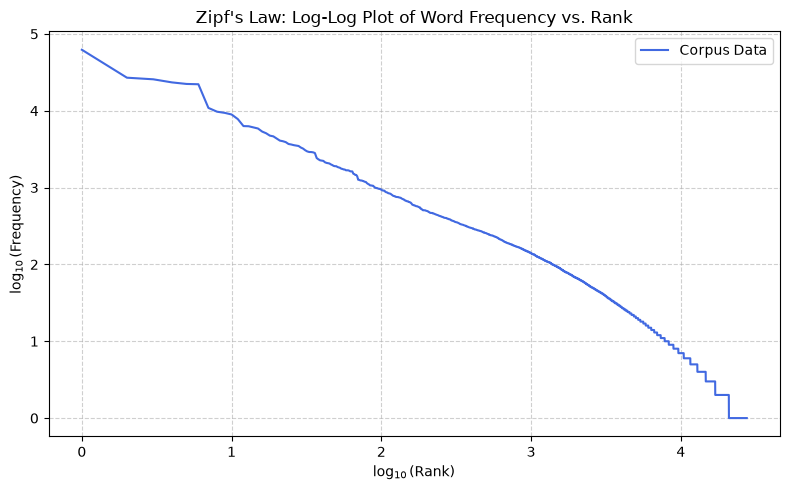

In [57]:
# TODO: Plot a graph of the log of the rank (starting at 1) on the x-axis,
# against the log of the frequency on the y-axis. You may use the matplotlib
# or other library.

import matplotlib.pyplot as plt
import numpy as np

# 1. Ranks start at 1 up to len(frequency)
ranks = np.arange(1, len(frequency) + 1)

# 2. Extract frequencies in ranked order
counts = np.array([count for word, count in frequency])

# 3. Compute logarithms (natural log or log10; log10 makes axis ticks easy to interpret)
log_ranks = np.log10(ranks)
log_counts = np.log10(counts)

# 4. Plot log(rank) vs log(frequency)
plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_counts, label='Corpus Data', color='royalblue')
plt.xlabel(r'$\log_{10}(\mathrm{Rank})$')
plt.ylabel(r'$\log_{10}(\mathrm{Frequency})$')
plt.title("Zipf's Law: Log-Log Plot of Word Frequency vs. Rank")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [61]:
# TODO: Compute the number of tokens in the corpus.
# Remember to count each occurrence of each word. For instance, the 62,216
# instances of "the" will all count here.
ntokens = 0

ntokens = sum(count for word, count in frequency)
print(f"Total tokens: {ntokens:,}")

Total tokens: 1,000,000


In [62]:
# TODO: Compute the proportion of tokens made up by the top 10 most
# frequent words.

top_10_token_count = sum(count for word, count in frequency[:10])
prop_top_10 = top_10_token_count / ntokens

print(f"Top 10 token count: {top_10_token_count:,}")
print(f"Proportion of corpus: {prop_top_10:.4f} ({prop_top_10 * 100:.2f}%)")

Top 10 token count: 221,568
Proportion of corpus: 0.2216 (22.16%)


In [63]:
# TODO: Compute the proportion of tokens made up by the words that occur
# exactly once in this collection.

# 1. Filter frequency list for words that occur exactly once
hapax_tokens = sum(count for word, count in frequency if count == 1)

# 2. Divide by total tokens
prop_hapax = hapax_tokens / ntokens

print(f"Number of hapax legomena tokens: {hapax_tokens:,}")
print(f"Proportion of corpus: {prop_hapax:.4f} ({prop_hapax * 100:.2f}%)")

Number of hapax legomena tokens: 6,641
Proportion of corpus: 0.0066 (0.66%)


## Acquiring New Documents (CS6200)

This section is required for students in CS6200 and worth up to 10 points extra credit for students in CS4220.

For this assignment so far, you've worked with data that's already been extracted, tokenized, and counted. In this final section, you'll explore acquiring new data.

One common way of acquiring data is through application programming interfaces (APIs) to various databases. The Library of Congress's [_Chronicling America_](https://www.loc.gov/collections/chronicling-america/about-this-collection/) site aggregates digitized US newspapers from the past two hundred years, such as the [_Milwaukee Leader_](https://www.loc.gov/resource/sn83045293/1926-09-26/ed-1/) from 100 years ago.

You can use [the API](https://libraryofcongress.github.io/data-exploration/loc.gov%20JSON%20API/Chronicling_America/README.html) to retrieve JSON data listing all issues of the _Milwaukee Leader_ from 1926: https://www.loc.gov/item/sn83045293/?st=calendar&year=1926&fo=json

Note the list in the `issue_data` field. For example, here is the record for the January 17, 1926, issue: https://www.loc.gov/item/sn83045462/1920-04-21/ed-1/. To get the information structured in JSON from the API, we append `?fo=json`, i.e.: https://www.loc.gov/item/sn83045462/1920-04-21/ed-1/?fo=json

In that issue record, you'll see links to data about individual pages in various data formats, such as JPEG, PDF, XML, and plain text, which is what we want here: https://tile.loc.gov/text-services/word-coordinates-service?segment=/service/ndnp/dlc/batch_dlc_ixtl_ver01/data/sn83045462/00280656732/1920042101/0366.xml&format=alto_xml&full_text=1

This plain text was transcribed from the digital images of the microfilm of old pages using optical character recognition (OCR) models, and so contains errors.

Your task is to acquire and analyze the issues of the _Milwaukee Leader_ from the month of September, 1926, i.e., the issues with a date field that starts with `1926-09`. This should be about the same amount of data as the million words from the Associated Press you analyzed in the last section.

Write code that calls the _Chronicling America_ API to download and extract the text from the _Milwaukee Leader_ from September 1926. You can use the `json` library from above and any other libraries you wish to fetch data from URLs. As you would when working with any production API, you may need to limit your rate of requests.

In [66]:
# TODO: Data acquisition code here.

import json
import time
import urllib.request

HEADERS = {'User-Agent': 'CS6200-IR-Coursework/1.0'}
WORD_COORD_SERVICE = "https://tile.loc.gov/text-services/word-coordinates-service"

def fetch_json(url, retries=3):
    for attempt in range(retries):
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=15) as resp:
                return json.loads(resp.read().decode('utf-8'))
        except Exception as e:
            if attempt == retries - 1:
                raise e
            time.sleep(1.0)

def fetch_text(url, retries=3):
    for attempt in range(retries):
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=15) as resp:
                return resp.read().decode('utf-8', errors='ignore')
        except Exception as e:
            if attempt == retries - 1:
                raise e
            time.sleep(1.0)

# 1. Fetch 1926 calendar and filter for September 1926 issues
calendar_url = "https://www.loc.gov/item/sn83045293/?st=calendar&year=1926&fo=json"
calendar_data = fetch_json(calendar_url)

if 'issue_data' in calendar_data:
    raw_issues = calendar_data['issue_data']
elif 'calendar' in calendar_data and 'issue_data' in calendar_data['calendar']:
    raw_issues = calendar_data['calendar']['issue_data']
else:
    raw_issues = next(v['issue_data'] for v in calendar_data.values() if isinstance(v, dict) and 'issue_data' in v)

sept_issues = [item for item in raw_issues if item['date'].startswith('1926-09')]

# 2. Download plain text OCR for each page
documents = []
print(f"Starting download for {len(sept_issues)} September 1926 issues...\n")

for i, issue in enumerate(sept_issues, start=1):
    issue_date = issue['date']
    issue_url = issue['urls'][0]['url'].rstrip('/') + '/?fo=json'
    
    print(f"[{i}/{len(sept_issues)}] Fetching issue: {issue_date}")
    
    try:
        issue_json = fetch_json(issue_url)
    except Exception as e:
        print(f"  Error fetching issue metadata: {e}")
        continue

    resource = issue_json['resources'][0]
    pages = resource.get('files', [])

    for page_idx, file_list in enumerate(pages, start=1):
        xml_url = None
        for f in file_list:
            if f.get('mimetype') == 'text/xml' and f.get('url'):
                xml_url = f['url']
                break
                
        if not xml_url:
            continue

        segment_path = xml_url.split('.gov/storage-services')[-1]
        text_service_url = f"{WORD_COORD_SERVICE}?segment={segment_path}&format=alto_xml&full_text=1"

        try:
            ocr_text = fetch_text(text_service_url)
            documents.append({
                'id': f"sn83045293_{issue_date}_p{page_idx}",
                'text': ocr_text
            })
        except Exception as e:
            print(f"  Failed page {page_idx}: {e}")

        time.sleep(0.05)

    time.sleep(0.2)

print(f"\nFinished! Successfully acquired {len(documents)} pages of text.")

Starting download for 25 September 1926 issues...

[1/25] Fetching issue: 1926-09-01
[2/25] Fetching issue: 1926-09-02
[3/25] Fetching issue: 1926-09-03
[4/25] Fetching issue: 1926-09-04
[5/25] Fetching issue: 1926-09-05
[6/25] Fetching issue: 1926-09-08
[7/25] Fetching issue: 1926-09-09
[8/25] Fetching issue: 1926-09-10
[9/25] Fetching issue: 1926-09-11
[10/25] Fetching issue: 1926-09-12
[11/25] Fetching issue: 1926-09-14
[12/25] Fetching issue: 1926-09-15
[13/25] Fetching issue: 1926-09-16
[14/25] Fetching issue: 1926-09-17
[15/25] Fetching issue: 1926-09-18
[16/25] Fetching issue: 1926-09-19
[17/25] Fetching issue: 1926-09-21
[18/25] Fetching issue: 1926-09-22
[19/25] Fetching issue: 1926-09-23
[20/25] Fetching issue: 1926-09-24
[21/25] Fetching issue: 1926-09-25
[22/25] Fetching issue: 1926-09-26
[23/25] Fetching issue: 1926-09-28
[24/25] Fetching issue: 1926-09-29
[25/25] Fetching issue: 1926-09-30

Finished! Successfully acquired 368 pages of text.


Write code to tokenize the text and count the resulting terms in each document. Since this data comes from automatically transcribing printed pages, some words may be hyphenated across line breaks. There is more than one right way to tokenize this data, so add comments to your code documenting your choices.

In [67]:
# TODO: Tokenization code here.

import re
from collections import Counter

# Resulting list to store term records: [{'id': ..., 'term': ..., 'count': ...}, ...]
ml_terms = []

for doc in documents:
    doc_id = doc['id']
    raw_text = doc['text']
    
    # 1. Handle OCR hyphenation across line breaks (e.g., "wash-\nington" -> "washington")
    cleaned_text = re.sub(r'(\w+)-\s*\n\s*(\w+)', r'\1\2', raw_text)
    
    # 2. Case normalization
    cleaned_text = cleaned_text.lower()
    
    # 3. Tokenize: extract alphabetic word sequences (ignoring isolated punctuation/OCR speckles)
    tokens = re.findall(r'\b[a-z]+\b', cleaned_text)
    
    # 4. Count term frequencies within this document
    term_counts = Counter(tokens)
    
    # 5. Build term records matching the APW schema
    for term, count in term_counts.items():
        ml_terms.append({
            'id': doc_id,
            'term': term,
            'count': count
        })

print(f"Total term records created: {len(ml_terms):,}")
if ml_terms:
    print("Sample record:", ml_terms[0])

Total term records created: 632,583
Sample record: {'id': 'sn83045293_1926-09-01_p1', 'term': 'service', 'count': 1}


Plot a graph of the log rank against log frequency for your collection, as you did for the sample collection above.

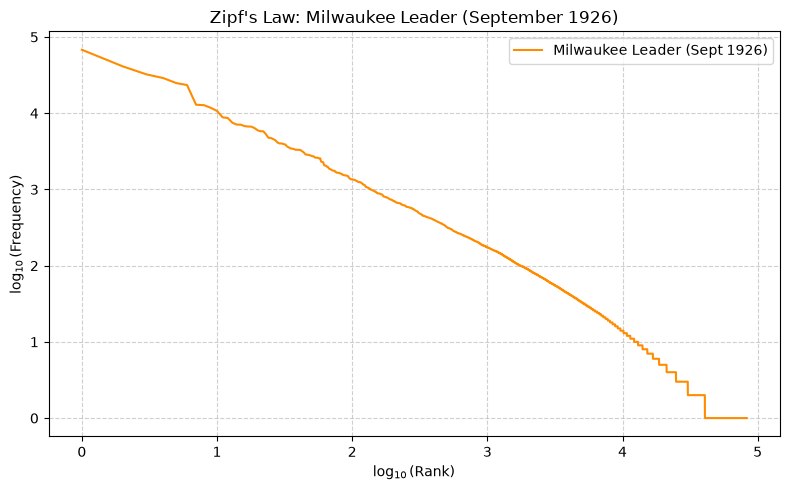

In [68]:
# TODO: Plotting code here.

import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# 1. Aggregate word counts across the entire Milwaukee Leader collection
ml_word_counts = Counter()
for record in ml_terms:
    ml_word_counts[record['term']] += record['count']

# 2. Sort by frequency descending: list of (word, count)
ml_frequency = ml_word_counts.most_common()

# 3. Create ranks (1 to V) and frequencies
ranks = np.arange(1, len(ml_frequency) + 1)
counts = np.array([count for _, count in ml_frequency])

# 4. Compute log10 values for both axes
log_ranks = np.log10(ranks)
log_counts = np.log10(counts)

# 5. Plot the Zipf's Law distribution
plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_counts, label='Milwaukee Leader (Sept 1926)', color='darkorange')
plt.xlabel(r'$\log_{10}(\mathrm{Rank})$')
plt.ylabel(r'$\log_{10}(\mathrm{Frequency})$')
plt.title("Zipf's Law: Milwaukee Leader (September 1926)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [69]:
# TODO: Compute the proportion of tokens made up by the top 10 most
# frequent words in this collection.

# 1. Total tokens in the Milwaukee Leader collection
ml_ntokens = sum(count for _, count in ml_frequency)

# 2. Sum of occurrences for the top 10 most frequent words
ml_top_10_count = sum(count for _, count in ml_frequency[:10])

# 3. Proportion
ml_prop_top_10 = ml_top_10_count / ml_ntokens

print(f"Total tokens in collection: {ml_ntokens:,}")
print(f"Top 10 words token count:   {ml_top_10_count:,}")
print(f"Proportion (top 10):        {ml_prop_top_10:.4f} ({ml_prop_top_10 * 100:.2f}%)")
print("\nTop 10 words:", [word for word, _ in ml_frequency[:10]])

Total tokens in collection: 1,467,417
Top 10 words token count:   266,983
Proportion (top 10):        0.1819 (18.19%)

Top 10 words: ['the', 'of', 'and', 'to', 'a', 'in', 'nthe', 'n', 'for', 'is']


In [70]:
# TODO: Compute the proportion of tokens made up by the words that occur
# exactly once in this collection.

# 1. Sum of tokens that occur exactly once (count == 1)
ml_hapax_count = sum(count for _, count in ml_frequency if count == 1)

# 2. Proportion
ml_prop_hapax = ml_hapax_count / ml_ntokens

print(f"Total hapax tokens (count == 1): {ml_hapax_count:,}")
print(f"Proportion (hapax legomena):     {ml_prop_hapax:.4f} ({ml_prop_hapax * 100:.2f}%)")

Total hapax tokens (count == 1): 42,364
Proportion (hapax legomena):     0.0289 (2.89%)


What do you observe about the differences between the distributions of the Associated Press and Milwaukee Leader collections?

**TODO: Describe the differences between the AP and the Milwaukee Leader word frequency distributions. Describe some possible reasons for these differences.**


### Comparison of Word Frequency Distributions: AP vs. *Milwaukee Leader*

#### 1. Observed Differences

* **Tail Behavior and Hapax Legomena:**
    * **Hapax token share:** In the Associated Press corpus, words occurring exactly once account for only **0.66%** of total tokens (6,641 tokens). In the *Milwaukee Leader*, hapax legomena account for **2.89%** of tokens (42,364 tokens)—over **4.3 times higher**.
    * **Vocabulary growth (Log-Log tail):** In the AP plot, the tail flattens out around $\log_{10}(\text{Rank}) \approx 4.4$ ($\sim 25,000$ unique types). In the *Milwaukee Leader* plot, the tail extends nearly to $\log_{10}(\text{Rank}) \approx 4.9$ ($\sim 85,000$ unique types), creating a much wider flat plateau at frequency 1 ($y = 0$).




* **Top 10 Words Proportion:**
    * The top 10 most frequent words comprise **22.16%** of all tokens in AP, but only **18.19%** in the *Milwaukee Leader*.


* **Top Word Composition & Noise:**
    * The AP top words consist entirely of standard English closed-class words (`the`, `of`, `to`, `a`, `and`, etc.).
    * The *Milwaukee Leader* top 10 includes noise artifacts: `'nthe'` and `'n'` appear alongside `'the'`, `'of'`, and `'and'`.



---

#### 2. Reasons for These Differences

* **OCR Transcription Noise:** 
    * The AP corpus is modern, clean digital text. The *Milwaukee Leader* collection comes from automatic Optical Character Recognition (OCR) applied to 100-year-old microfilmed print.
    * Ink smudges, uneven print impression, and paper degradation produce thousands of slight character misrecognitions (e.g., `the` recognized as `tbe`, `thc`, or joined with adjacent punctuation as `nthe`).
    * Because each specific typo occurs only once or twice, OCR errors drastically inflate the count of distinct low-frequency words, expanding the hapax legomena tail.


* **Fragmentation and Line Wraps:**
    * Historic newspapers relied on narrow vertical columns requiring frequent hyphenation across lines. Despite basic de-hyphenation handling, broken words, standalone characters (like isolated `n`), and stray symbols remain in the vocabulary, dispersing probability mass away from standard words.


* **Degradation of High-Frequency Words:**
    * The true occurrences of the top function words (especially `the`) are partially fractured into noisy variants like `nthe`, pulling probability mass out of the true top ranks and lowering the aggregate share of the top 10 words from 22.16% to 18.19%.


* **Genre and Historical Register:**
    * The AP corpus reflects modern 21st-century broadcast wire journalism, whereas the *Milwaukee Leader* reflects 1920s local, editorial, and labor-movement press with archaic idioms, regional names, and printed advertising copy.